In [1]:
#<------- RUN ME

install.packages("gutenbergr")
library(gutenbergr)
library(tidyverse)
install.packages("remotes")
library(remotes)
remotes::install_github("Julianj22/ResearchR", force=TRUE)
library(ResearchR)
library(stringr)
install.packages("tokenizers")


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘triebeard’, ‘readMDTable’, ‘urltools’


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)





── R CMD build ─────────────────────────────────────────────────────────────────
* checking for file ‘/tmp/RtmpvrWLOj/remotes40a40f05eca/Julianj22-ResearchR-57b2773/DESCRIPTION’ ... OK
* preparing ‘ResearchR’:
* checking DESCRIPTION meta-information ... OK
* checking for LF line-endings in source and make files and shell scripts
* checking for empty or unneeded directories
Omitted ‘LazyData’ from DESCRIPTION
* building ‘ResearchR_0.1.0.tar.gz’



Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘SnowballC’




# **Loudness in the Novel** 🐛

### AP Research CT

<img src="https://ik.imagekit.io/panmac/tr:f-auto,w-740,pr-true/bcd02f72-b50c-0179-8b4b-5e44f5340bd4/84f9dc39-0868-4cec-aeaa-2356387f37ce/Alice%E2%80%99s%20Adventures%20in%20Wonderland%20-%20Header.png" width="50%">

*In this module, you will be discovering trends in the voice and sound of a novel, as discussed in this module's primary document: Loudness in the Novel (Katsma, 2014). **Research in the literary arts** is a broad group of studies aimed at better understanding human expression and societal, historical structures through written work. Some questions in literary analysis and historical linguistics are too complex or infeasible for a single human or group of humans to figure out on their own. This is where computers—but more crucially, computational thinking—play a role. **Throughout the course of this module, you will choose a research subject, calculate metrics from text data, visualize structural pacing, and communicate your findings using evidence from the study.***

## **Research Question**

<img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRA43fA1FCH576bPSGmt-YC2gdvy-WfpT1DPs43L2BycQ&s=10" width="45%">

#### Background


**How might we measure narrative loudness—or how loudly characters are perceived as speaking—in a novel?** This is the central question that Katsma (2014) asks in his paper, Loudness in the Novel, and is what will guide much of the work in this module. Instead of choosing a research question, you will choose a subject of study (a text), and follow Katsma's methods to understand the following: ​

​​<br>

**​To what extent does the narrative loudness and pacing contour of [TEXT 1] differ from [TEXT 2]?​**
​​
<br>
<br>

​Choose two texts from the following list:​

<br>

* **Alice in Wonderland**, by Lewis Carroll​
* **Dracula**, by Bram Stoker​
* **Hamlet**, by William Shakespeare​
* **Romeo and Juliet**, by William Shakespeare
* **Macbeth**, by William Shaksespeare
* **Moby Dick**, by Herman Melville​
* **Oedipus the King**, by Sophocles​
* **Oliver Twist**, by Charles Dickens​
* **The Adventures of Huckleberry Finn**, by Mark Twain​
* **The Adventures of Sherlock Holmes**, by Arthur Conan Doyle​
* **The Jungle**, by Upton Sinclair​
* **The Phantom of the Opera**, by Gaston Leroux​
* **The Wonderful Wizard of Oz**, by Frank Baum​
* **Through the Looking Glass**, by Lewis Carroll​
* **Ulysses**, by James Joyce
* **The Great Gatsby**, by F. Scott Fitzgerald
* **Sense and Sensibility**, by Jane Austen
* **Pride and Prejudice**, by Jane Austen

**My Question:**

​To what extent does the narrative loudness and pacing contour of The Great Gatsby differ from Pride and Prejudice?



---



## **Data Collection**

### Methodology

Unlike other research papers you may have examined, *Loudness in the Novel* (2014), employs neither an experimental nor observational study.  Instead, discoveries are made in the analysis of text. To start, **what are the two methods Katsma uses to measure narrative loudness in a text.** ​

Punctuation and speaking verbs. 

After you have identified the two methods, use this excerpt from *Pride and Prejudice* (1813) to practice using them. **What score does each method give to this piece of text?** Run the following line of code to view the excerpt.​

In [2]:
pp <- gutenberg_download(1342)

pp <- pp %>%
  mutate(chapter = cumsum(str_detect(text,
         regex("^\\s*chapter\\s+[0-9ivxlc]+\\.?\\s*$", ignore_case = TRUE))))

ch33 <- pp %>% filter(chapter == 33)

txt <- paste(ch33$text, collapse = " ") %>% str_squish()

start <- str_locate(txt, regex("Who that knows", ignore_case = TRUE))[1]

excerpt <- str_sub(txt, start, start + 1626)

cat(strwrap(str_sub(txt, start, start + 1626), width = 80), sep = "\n")



Using mirror https://gutenberg.pglaf.org.


Who that knows what his misfortunes have been can help feeling an interest in
him?” “His misfortunes!” repeated Darcy, contemptuously,--“yes, his misfortunes
have been great indeed.” “And of your infliction,” cried Elizabeth, with
energy; “You have reduced him to his present state of poverty--comparative
poverty. You have withheld the advantages which you must know to have been
designed for him. You have deprived the best years of his life of that
independence which was no less his due than his desert. You have done all this!
and yet you can treat the mention of his misfortunes with contempt and
ridicule.” “And this,” cried Darcy, as he walked with quick steps across the
room, “is your opinion of me! This is the estimation in which you hold me! I
thank you for explaining it so fully. My faults, according to this calculation,
are heavy indeed! But, perhaps,” added he, stopping in his walk, and turning
towards her, “these offences might have been overlooked, had not your pride
been hurt 

### Import

To work with our data, we need to first import it into our environment—meaning, we just need to have it on our screen, to be able to work with it. Run the following line of code to view the dataset.

In [3]:
# RUN ME AFTER INSERTING TEXT TITLES BELOW

my_texts <- c(
  "Alice in Wonderland"                 = 11,
  "Dracula"                             = 345,
  "Hamlet"                              = 1524,
  "Romeo and Juliet"                    = 1513,
  "Macbeth"                             = 1533,
  "Moby Dick"                           = 2701,
  "Oedipus the King"                    = 27673,
  "Oliver Twist"                        = 730,
  "The Adventures of Huckleberry Finn"  = 76,
  "The Adventures of Sherlock Holmes"   = 1661,
  "The Jungle"                          = 140,
  "The Phantom of the Opera"            = 175,
  "The Wonderful Wizard of Oz"          = 55,
  "Through the Looking Glass"           = 12,
  "Ulysses"                             = 4300,
  "The Great Gatsby"                    = 64317,
  "Sense and Sensibility"               = 161,
  "Pride and Prejudice"                 = 1342
)

# ---- EDIT THIS LINE ----
text_title_1 <- "The Great Gatsby"
text_title_2 <- "Pride and Prejudice"
text1 <- gutenberg_download(my_texts[[text_title_1]], meta_fields = "title")

text2 <- gutenberg_download(my_texts[[text_title_2]], meta_fields = "title")



To test if you have imported correctly, run the following code.

In [4]:
# TEXT 1 CHECK

paragraphs <- text1$text |>
  paste(collapse = "\n") |>
  str_split("\n\\s*\n") |>
  unlist() |>
  str_squish()

paragraphs <- paragraphs[paragraphs != ""]

paste(paragraphs[c(25)], collapse = " ")



[1] "Why they came East I don’t know. They had spent a year in France for no particular reason, and then drifted here and there unrestfully wherever people played polo and were rich together. This was a permanent move, said Daisy over the telephone, but I didn’t believe it—I had no sight into Daisy’s heart, but I felt that Tom would drift on forever seeking, a little wistfully, for the dramatic turbulence of some irrecoverable football game."

In [5]:
# TEXT 2 CHECK

paragraphs <- text2$text %>%
  paste(collapse = "\n") %>%
  str_split("\n\\s*\n") %>%
  unlist() %>%
  str_squish()

paragraphs <- paragraphs[paragraphs != ""]

paste(paragraphs[c(29)], collapse = " ")

[1] "_The Bingleys and the Gardiners and the Lucases, Miss Darcy and Miss de Bourgh, Jane, Wickham, and the rest, must pass without special comment, further than the remark that Charlotte Lucas (her egregious papa, though delightful, is just a little on the thither side of the line between comedy and farce) is a wonderfully clever study in drab of one kind, and that Wickham (though something of Miss Austen’s hesitation of touch in dealing with young men appears) is a not much less notable sketch in drab of another. Only genius could have made Charlotte what she is, yet not disagreeable; Wickham what he is, without investing him either with a cheap Don Juanish attractiveness or a disgusting rascality. But the hero and the heroine are not tints to be dismissed._"

## **Data Visualization**

### Emulation




To communicate *how loud* a text is, it may be best practice to visualize these trends using technology. But first, we must **compute** loudness for a text in order to plot it. Fortunately, Katsma establishes two methods of doing so. To compute a *loudness metric* for any given text, let us begin by emulating (or copying) Katsma's first method.​

#### Method 1: Speaking Verbs


Speaking verbs are words that typically tell us when a character is speaking in a narrative, and how. Some examples include:​
<br><br>
​​
* "I didn't want to go to the park, anyway," she **said**. ​
* He **cried** after his love, "I will never forgive you!"​
* The prince **whispered** to his council.​
* They all gasped and **exclaimed**: "The killer!"<br><br>

Katsma proposes that by counting the number of speaking verbs in a text, we can measure that text's loudness. Modify the code below to meet this aim:​
​

In [6]:
naive_loudness_score <- function(chapter_string) {
  neutral_verbs <- c("said", "replied", "observed", "rejoined", "asked",
                     "answered", "returned", "repeated", "remarked",
                     "enquired", "responded")

  resonant_verbs <- c("picked up", "warmly approved", "added", "continued",
                      "began", "started")

  med_loud_verbs <- c("retorted", "interrupted", "said sternly", "objected",
                      "protested", "declared", "announced")

  loud_verbs <- c("said loudly", "interrupted hotly", "called", "bawled",
                  "vociferated", "proclaimed")

  #____EDIT ME_____#
  very_loud_verbs <- c("shouted")
  #____EDIT ME_____#

  verbs <- list(neutral_verbs, resonant_verbs, med_loud_verbs,
                loud_verbs, very_loud_verbs)

  text <- str_to_lower(chapter_string)


  sum(sapply(seq_along(verbs), function(i) {
    if (length(verbs[[i]]) == 0) return(0)
    sum(str_count(text, fixed(verbs[[i]]))) * (i - 1)
  }))
}


Now, let's test this function on the except from earlier that we scored ourselves. **Run the following line of code to view the excerpt’s loudness score.** The higher the score, the louder the narrative. **Does it differ from the one you came up with for method 1?** Why might this be if so?

In [7]:
naive_loudness_score(excerpt)

[1] 1

#### Method 2: Grammatical Intensity

Crucially, Katsma argues that rather than simply count speaking verbs, one might gain a better idea of loudness in a novel by measuring the grammar of a scene. He sections his thinking into three to four main structures, which have been partially implemented in the code below. **You need not modify anything here— just run the cell.**

In [8]:
library(stringr)

adv_loudness_score <- function(sentence) {
  lower_sentence <- str_to_lower(sentence)


  structure1 <- str_count(lower_sentence, "[\\p{L}\\p{N}]+ me")


  structure2 <- as.integer(
    str_detect(sentence, fixed("?")) &
    str_detect(lower_sentence, "what|why|how")
  )


  punc_count <- str_count(sentence, "!|\u2014|--")
  word_count <- str_count(lower_sentence, "oh|dear|god|heaven")
  structure3 <- punc_count + word_count

  structure1 + structure2 + structure3
}


In your own words, **what is this function doing?** Or, **what are we trying to tell the computer to do?​**

​Now, run the code below to compute our new loudness score for the same Pride and Prejudice excerpt. Again, the higher the score, the louder the narrative.

In [9]:
adv_loudness_score(excerpt)

[1] 13

**Does this result differ from the one you came up with for method 2?** Why might this be if so?​

### Graphing


Now that we have a way to compute loudness, lets create some visualizations. Notice that Katsma computes loudness for each sentence, then calculates what is called the moving average over all of the sentences in the novel. The *moving average* is like your typical average, except it allows us to more clearly see trends over time.

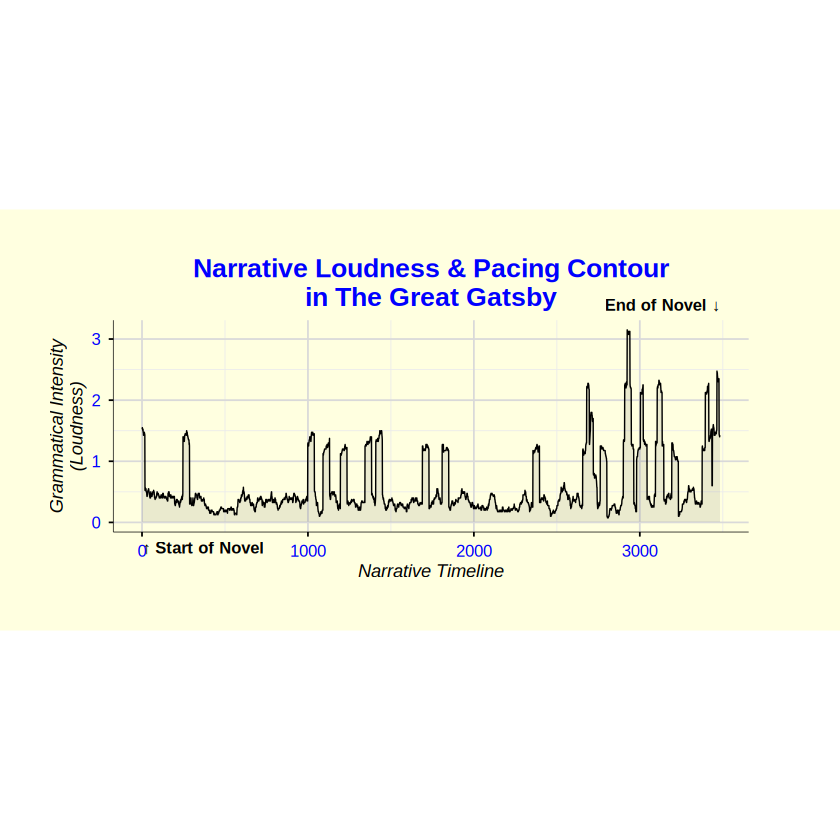

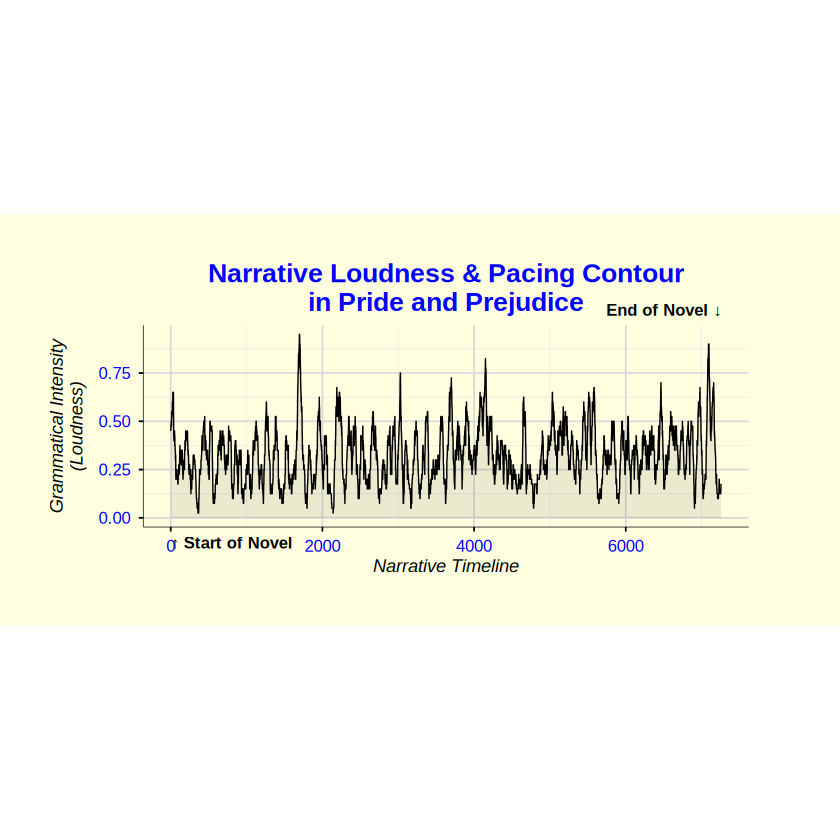

In [10]:

library(tokenizers)
library(ggplot2)
library(dplyr)

plot_loudness <- function(text, label, window = 40) {

  if (is.data.frame(text)) text <- text$text
  text <- paste(text, collapse = " ")

  sentences <- tokenizers::tokenize_sentences(text, simplify = TRUE)
  scores <- adv_loudness_score(sentences)

  if (length(scores) < window) {
    window <- max(1, floor(length(scores) / 2))
    message("Only ", length(scores), " sentences; using window = ", window)
  }

  ma <- as.numeric(stats::filter(scores, rep(1 / window, window), sides = 1))
  ma <- ma[!is.na(ma)]

  df <- dplyr::tibble(x = seq_along(ma), y = ma)

  ggplot2::ggplot(df, ggplot2::aes(x, y)) +
    ggplot2::geom_area(alpha = 0.1) +
    ggplot2::geom_line(linewidth = 0.4) +
    ggplot2::annotate("text", x = min(df$x), y = -Inf,
             label = "\u2191 Start of Novel",
             hjust = 0, vjust = 1.8, size = 3.5, fontface = "bold") +
    ggplot2::annotate("text", x = max(df$x), y = Inf,
             label = "End of Novel \u2193",
             hjust = 1, vjust = -0.8, size = 3.5, fontface = "bold") +
    ggplot2::coord_cartesian(clip = "off") +
    ggplot2::labs(
      title = paste0("Narrative Loudness & Pacing Contour\nin ", label),
      x = "Narrative Timeline",
      y = "Grammatical Intensity\n(Loudness)"
    ) +
    ggplot2::theme_minimal(base_size = 11) +
    ggplot2::theme(
      aspect.ratio = 1 / 3,
      plot.title = ggplot2::element_text(size = 16, face = "bold", hjust = 0.5, colour = "blue"),
      axis.title = ggplot2::element_text(face = "italic"),
      axis.line = ggplot2::element_line(colour = "black", linewidth = 0.2),
      axis.ticks = ggplot2::element_line(colour = "black"),
      axis.text = ggplot2::element_text(colour = "blue", size = 10),
      panel.grid.major = ggplot2::element_line(colour = "grey85"),
      plot.background = ggplot2::element_rect(fill = "lightyellow", colour = NA),
      plot.margin = ggplot2::margin(30, 55, 30, 30)
    )
}

plot_loudness(text1, "The Great Gatsby")
plot_loudness(text2, "Pride and Prejudice")


**Et voilà!** We have got our graphs. Now, make them even better:​

* Edit at least three parts of each graph. This can be changing the name of the title, color of the line, etc.​
​ ​

#### Trends

What trends or patterns seem to appear in your data? What might these say about your research question? Do your findings make sense to you intuitively?

The Great Gatsby seems like it is a quieter book compared to Pride and Prejudice and Pride and Prejudice seems more consistent in its loudness compared to how the Great Gatsby has sudden moments of loudness. Intuitively this does make sense because at the end of Great Gatsby there is a scene where Mrytle gets hit by a car and Gatsby gets shot and so this would cause the book to be loud. 



---



## **Results**


While it may seem that we are done with our analysis, we must still support our conclusions empirically, meaning with hard evidence—it is never enough to just look at a graph. Keep in mind that we would essentially like to understand which of our texts is **louder**. ​
​​
​One idea, may be to calculate the area under the curve of our lines. The code that does this is left below. Which text is louder by this standard?

In [ ]:
loudness_curve <- function(text, window = 40) {
  if (is.data.frame(text)) text <- text$text
  text <- paste(text, collapse = " ")

  sentences <- tokenize_sentences(text, simplify = TRUE)
  scores <- adv_loudness_score(sentences)

  if (length(scores) < window) {
    window <- max(1, floor(length(scores) / 2))
    message("Only ", length(scores), " sentences; using window = ", window)
  }

  ma <- as.numeric(stats::filter(scores, rep(1 / window, window), sides = 1))
  ma <- ma[!is.na(ma)]

  tibble(x = seq_along(ma), y = ma)
}
average_loudness <- function(text, window = 40, method = c("linear", "spline")) {
  method <- match.arg(method)

  y <- loudness_curve(text, window)$y
  n <- length(y)
  x <- seq_len(n)

  if (method == "linear") {

    area <- sum((y[-n] + y[-1]) / 2)
  } else {

    f <- splinefun(x, y, method = "natural")
    area <- sum(vapply(x[-n], function(i) integrate(f, i, i + 1)$value, numeric(1)))
  }

  area / (n - 1)
}

cat("Text 1 Loudness =", average_loudness(text1), "\n")
cat("Text 2 Loudness =", average_loudness(text2), "\n")


​
​​
​Based on your work in this module and the graphs above, **determine your own method for judging which text is louder.** This does not have to be implemented.

Our own method would be to look at the peaks, where they are and how often they show up. 

Moving average is when a few sentences are taken and the average of those sentences is what is being shown 

---



## **Conclusion**

<img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSwJ5sYiwY70kXjv_5gJpJXhxyZW9lsx_XYSXdxvdVJCNAx_cqe7O4F3YKy&s=10" width="40%">

### Discussion


Given everything you have learned in this module, **were you able to answer your research question?** If you were able to, detail what empirical evidence you've collected that supports this claim(s).

**​If you were not able to adequately answer your research question, ask yourself: could I have answered my question using only the data provided?** Was there something meaningful you learned about the topic regardless? ​

We were able to answer our research question because our graphs showed that the Great Gatsby was a lot higher since the scale goes above 1 while Pride and Prejudice's scale is below one.  

### Next Steps

How would you expand on the work of these researchers? Is there a different sample you would consider? A different research focus? Would you change how the research was conducted. Discuss this below.

I would expand on the work of researchers by comparing movies as well as novels. Since most famous novels have a movie adaptation I would compare the movie scripts to see if the loudness of both the novels and movies compare.